In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
DATA_PATH = "../dataset/raw/traffic_accidents.csv"
REPORT_PATH = "../reports"
MODEL_PATH = "../models"
OUTPUT_PATH = "../visualizations/advanced"

os.makedirs(OUTPUT_PATH, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Total records: 2301644
Columns: ['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']


In [3]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = [
    "crash_date",
    "crash_time",
    "borough",
    "number_of_persons_injured",
    "number_of_persons_killed",
    "contributing_factor_vehicle_1"
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df["crash_date"] = pd.to_datetime(df["crash_date"], errors="coerce")
df["crash_hour"] = pd.to_datetime(
    df["crash_time"], format="%H:%M", errors="coerce"
).dt.hour

df["injured"] = pd.to_numeric(
    df["number_of_persons_injured"], errors="coerce"
).fillna(0)

df["killed"] = pd.to_numeric(
    df["number_of_persons_killed"], errors="coerce"
).fillna(0)

df["severity"] = np.select(
    [df["killed"] > 0, df["injured"] > 0],
    ["Fatal", "Injury"],
    default="Property Damage"
)

df["year"] = df["crash_date"].dt.year
df["month"] = df["crash_date"].dt.month

print("Visualization data prepared!")

Visualization data prepared!


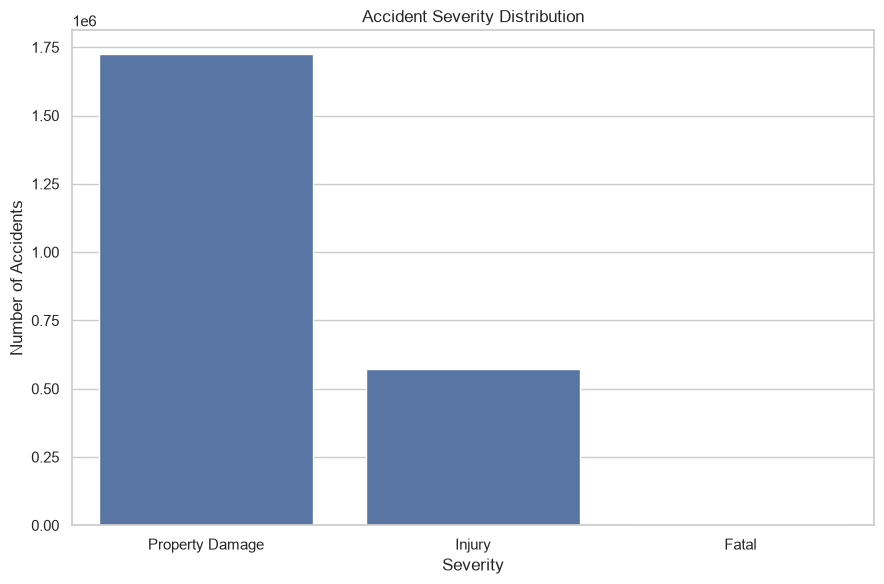

In [4]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="severity",
    order=["Property Damage", "Injury", "Fatal"]
)

plt.title("Accident Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Accidents")
plt.tight_layout()

plt.savefig(f"{OUTPUT_PATH}/severity_distribution.png", dpi=300)
plt.show()

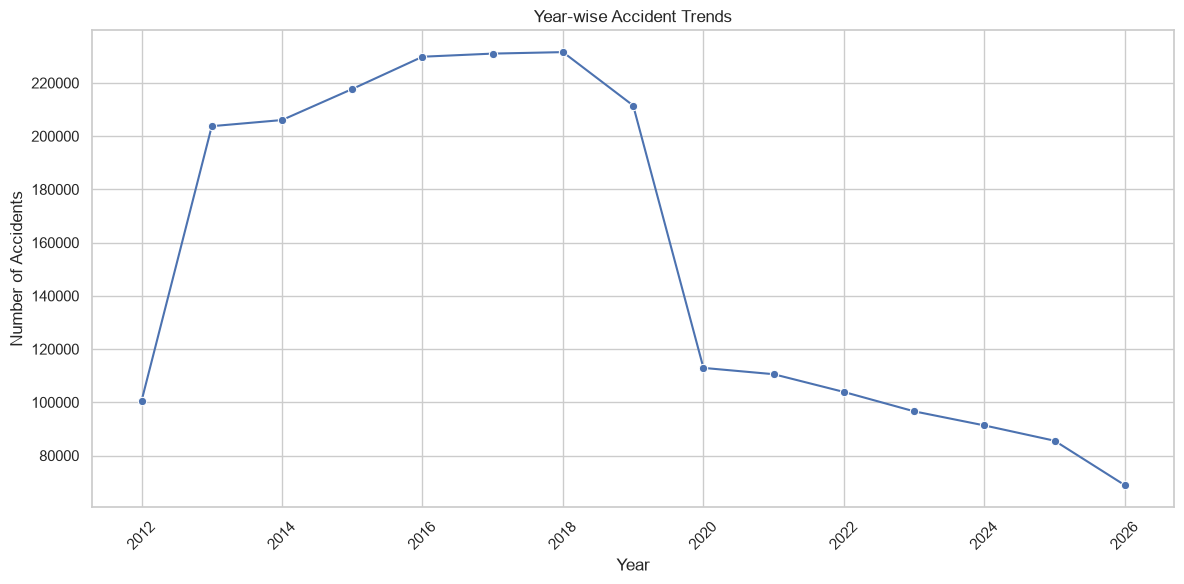

In [5]:
yearly = df.dropna(subset=["year"]).groupby("year").size()

plt.figure(figsize=(12, 6))
sns.lineplot(x=yearly.index, y=yearly.values, marker="o")

plt.title("Year-wise Accident Trends")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(f"{OUTPUT_PATH}/yearly_accident_trend.png", dpi=300)
plt.show()

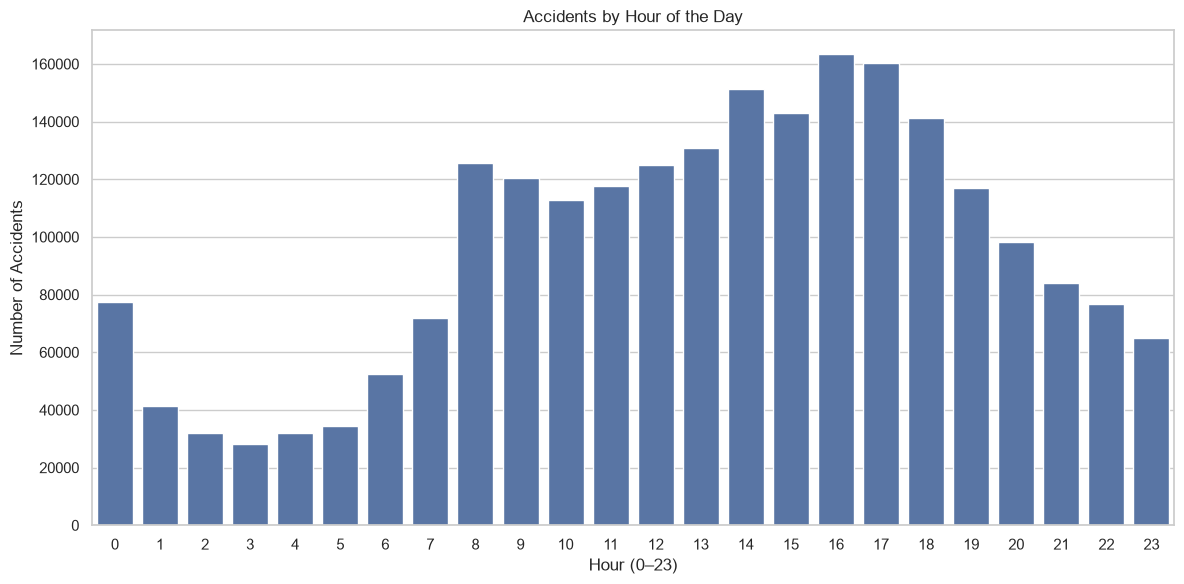

In [6]:
hourly = df.dropna(subset=["crash_hour"]).groupby("crash_hour").size()

plt.figure(figsize=(12, 6))
sns.barplot(x=hourly.index, y=hourly.values)

plt.title("Accidents by Hour of the Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Number of Accidents")
plt.tight_layout()

plt.savefig(f"{OUTPUT_PATH}/hourly_accident_analysis.png", dpi=300)
plt.show()

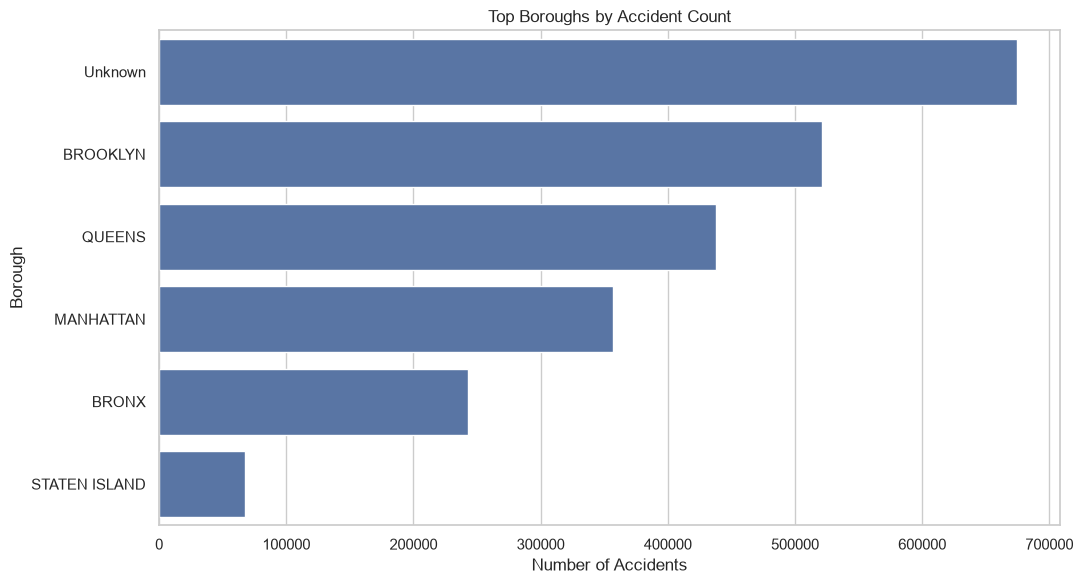

In [7]:
borough_data = (
    df["borough"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
)

plt.figure(figsize=(11, 6))
sns.barplot(x=borough_data.values, y=borough_data.index)

plt.title("Top Boroughs by Accident Count")
plt.xlabel("Number of Accidents")
plt.ylabel("Borough")
plt.tight_layout()

plt.savefig(f"{OUTPUT_PATH}/borough_accidents.png", dpi=300)
plt.show()

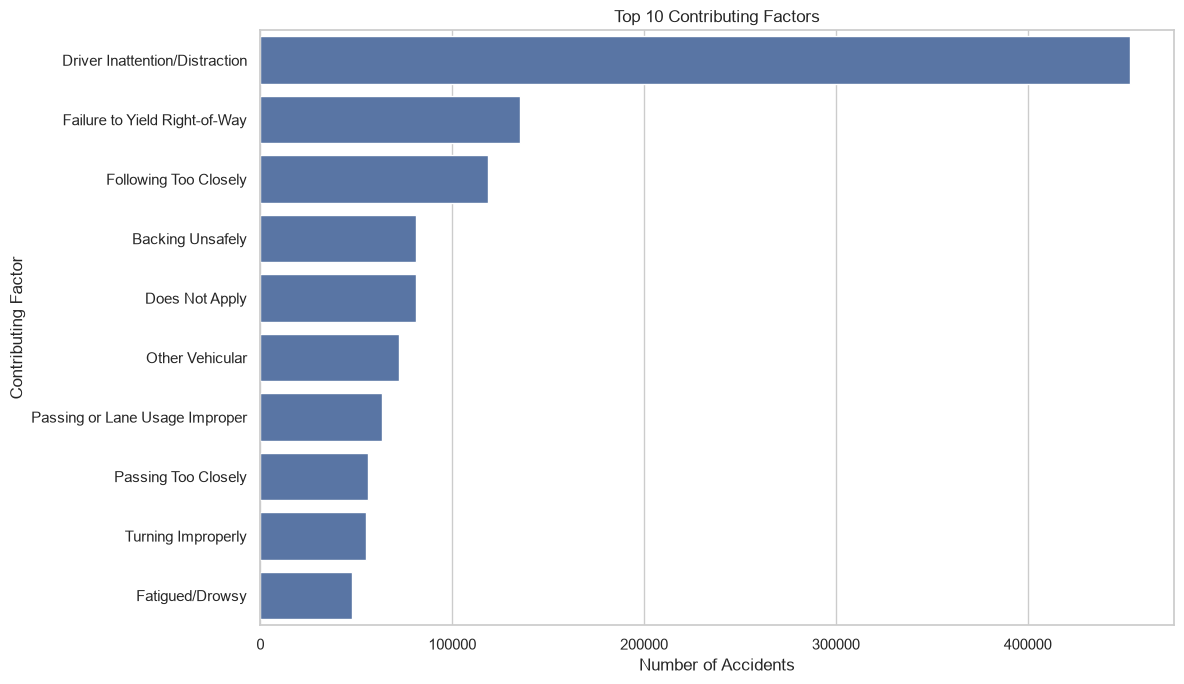

In [8]:
factor_data = (
    df["contributing_factor_vehicle_1"]
    .dropna()
    .loc[lambda x: x != "Unspecified"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 7))
sns.barplot(x=factor_data.values, y=factor_data.index)

plt.title("Top 10 Contributing Factors")
plt.xlabel("Number of Accidents")
plt.ylabel("Contributing Factor")
plt.tight_layout()

plt.savefig(f"{OUTPUT_PATH}/top_contributing_factors.png", dpi=300)
plt.show()

In [9]:
importance_path = os.path.join(REPORT_PATH, "feature_importance.csv")

if os.path.exists(importance_path):
    importance_df = pd.read_csv(importance_path)

    print("Feature importance columns:", importance_df.columns.tolist())
    display(importance_df.head(10))
else:
    print("feature_importance.csv not found. Check your reports folder.")

feature_importance.csv not found. Check your reports folder.


In [10]:
print("PHASE 7 VISUALIZATION SUMMARY")
print("--------------------------------")

print("Total accidents:", len(df))
print("\nSeverity distribution:")
print(df["severity"].value_counts())

print("\nTop 5 contributing factors:")
print(df["contributing_factor_vehicle_1"].value_counts().head(5))

print("\nAll visualization files saved in:", OUTPUT_PATH)

PHASE 7 VISUALIZATION SUMMARY
--------------------------------
Total accidents: 2301644

Severity distribution:
severity
Property Damage    1725037
Injury              573026
Fatal                 3581
Name: count, dtype: int64

Top 5 contributing factors:
contributing_factor_vehicle_1
Unspecified                       730550
Driver Inattention/Distraction    453543
Failure to Yield Right-of-Way     135268
Following Too Closely             118553
Backing Unsafely                   81161
Name: count, dtype: int64

All visualization files saved in: ../visualizations/advanced
